In [7]:
# Install ucimlrepo if not already installed
!pip install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fix random seed for reproducibility
SEED = 42
np.random.seed(SEED)

# Fetch Concrete Compressive Strength dataset (ID: 165)
concrete = fetch_ucirepo(id=165)
X_raw = concrete.data.features.copy()
y_raw = concrete.data.targets.squeeze().copy()

# Rename columns to clean, short names
X_raw.columns = [
    'cement', 'slag', 'fly_ash', 'water',
    'superplasticizer', 'coarse_agg', 'fine_agg', 'age'
]
y_raw.name = 'strength'

df = pd.concat([X_raw, y_raw], axis=1)
print("Initial dataset shape:", df.shape)
print("Missing values:\\n", df.isnull().sum())

Initial dataset shape: (1030, 9)
Missing values:\n cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age                 0
strength            0
dtype: int64


In [10]:
duplicates = df.duplicated().sum()
print("Duplicate rows found:", duplicates)

df_clean = df.drop_duplicates().reset_index(drop=True)
print("Shape after cleaning:", df_clean.shape)
print("Target (Strength) Range:", round(df_clean['strength'].min(), 2), "to", round(df_clean['strength'].max(), 2), "MPa")
print("Target Mean ± SD:", round(df_clean['strength'].mean(), 2), "±", round(df_clean['strength'].std(), 2), "MPa")

display(df_clean.describe().round(2))

Duplicate rows found: 25
Shape after cleaning: (1005, 9)
Target (Strength) Range: 2.33 to 82.6 MPa
Target Mean ± SD: 35.25 ± 16.28 MPa


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
count,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00
mean,278.63,72.04,55.54,182.08,6.03,974.38,772.69,45.86,35.25
std,104.34,86.17,64.21,21.34,5.92,77.58,80.34,63.73,16.28
min,102.00,0.00,0.00,121.80,0.00,801.00,594.00,1.00,2.33
25%,190.70,0.00,0.00,166.60,0.00,932.00,724.30,7.00,23.52
50%,265.00,20.00,0.00,185.70,6.10,968.00,780.00,28.00,33.80
75%,349.00,142.50,118.30,192.90,10.00,1031.00,822.20,56.00,44.87
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


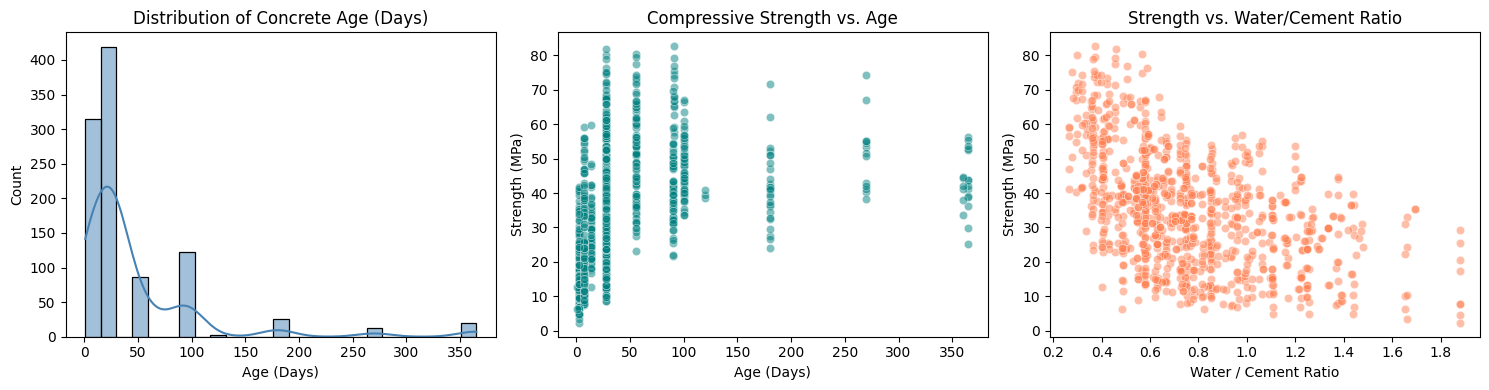

Correlation with Compressive Strength:
strength            1.000000
cement              0.488283
superplasticizer    0.344209
age                 0.337367
slag                0.103374
fly_ash            -0.080648
coarse_agg         -0.144717
fine_agg           -0.186448
water              -0.269624
Name: strength, dtype: float64


In [11]:
# Create water-to-cement ratio temporarily for EDA plot
df_clean['water_cement_ratio'] = df_clean['water'] / df_clean['cement']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Age histogram (showing right skew)
sns.histplot(df_clean['age'], bins=25, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Concrete Age (Days)')
axes[0].set_xlabel('Age (Days)')

# 2. Strength vs Age
sns.scatterplot(x='age', y='strength', data=df_clean, alpha=0.5, ax=axes[1], color='teal')
axes[1].set_title('Compressive Strength vs. Age')
axes[1].set_xlabel('Age (Days)')
axes[1].set_ylabel('Strength (MPa)')

# 3. Strength vs Water/Cement Ratio
sns.scatterplot(x='water_cement_ratio', y='strength', data=df_clean, alpha=0.5, ax=axes[2], color='coral')
axes[2].set_title('Strength vs. Water/Cement Ratio')
axes[2].set_xlabel('Water / Cement Ratio')
axes[2].set_ylabel('Strength (MPa)')

plt.tight_layout()
plt.savefig('eda_concrete.png', dpi=300)
plt.show()

# Drop temporary column before splitting
df_clean = df_clean.drop(columns=['water_cement_ratio'])

# Correlation with target
print("Correlation with Compressive Strength:")
print(df_clean.corr()['strength'].sort_values(ascending=False))

In [16]:
X = df_clean.drop(columns=['strength'])
y = df_clean['strength']

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Train samples:", len(X_train), "Test samples:", len(X_test))

# Function to add engineered features (water/cement ratio & log(age))
def add_engineered_features(data):
    d = data.copy()
    d['water_cement_ratio'] = d['water'] / d['cement']
    d['log_age'] = np.log1p(d['age'])
    return d

X_train_eng = add_engineered_features(X_train)
X_test_eng = add_engineered_features(X_test)

Train samples: 804 Test samples: 201


In [19]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    cv_scores = cross_val_score(model, X_tr, y_tr, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse_mean = -cv_scores.mean()
    cv_rmse_std = cv_scores.std()

    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)

    mae = mean_absolute_error(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    r2 = r2_score(y_te, preds)

    return cv_rmse_mean, cv_rmse_std, mae, rmse, r2, preds

# 1. Baseline: Linear Regression
lr_pipe = Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())])

# 2. Tuned Polynomial + Ridge Regression
poly_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures()),
    ('ridge', Ridge(random_state=SEED))
])
poly_params = dict(
    poly__degree=[2, 3],
    ridge__alpha=[0.1, 1.0, 10.0, 50.0]
)
poly_grid = GridSearchCV(poly_pipe, poly_params, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
poly_grid.fit(X_train_eng, y_train)
print("Best Poly+Ridge params:", poly_grid.best_params_)
best_poly = poly_grid.best_estimator_

# 3. Tuned Gradient Boosting Regressor
gbr = GradientBoostingRegressor(random_state=SEED)
gbr_params = dict(
    n_estimators=[100, 200, 300],
    max_depth=[3, 4, 5],
    learning_rate=[0.05, 0.1]
)
gbr_grid = GridSearchCV(gbr, gbr_params, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
gbr_grid.fit(X_train_eng, y_train)
print("Best Gradient Boosting params:", gbr_grid.best_params_)
best_gbr = gbr_grid.best_estimator_

# 4. MLP Regressor (Neural Network)
mlp_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, early_stopping=True, random_state=SEED))
])

models = [
    ('Linear Regression (Baseline)', lr_pipe),
    ('Polynomial + Ridge (Tuned)', best_poly),
    ('Gradient Boosting (Tuned)', best_gbr),
    ('MLP Regressor', mlp_pipe)
]

results_list = []
for name, model in models:
    _, _, mae_raw, rmse_raw, r2_raw, _ = evaluate_model(model, X_train, y_train, X_test, y_test)
    cv_m, cv_s, mae_eng, rmse_eng, r2_eng, preds_eng = evaluate_model(model, X_train_eng, y_train, X_test_eng, y_test)

    results_list.append(dict(
        Model=name,
        Raw_RMSE=round(rmse_raw, 2),
        Eng_CV_RMSE=str(round(cv_m, 2)) + " ± " + str(round(cv_s, 2)),
        Eng_MAE=round(mae_eng, 2),
        Eng_RMSE=round(rmse_eng, 2),
        Eng_R2=round(r2_eng, 3)
    ))
    if 'Gradient Boosting' in name:
        best_preds = preds_eng

results_df = pd.DataFrame(results_list)
display(results_df)

Best Poly+Ridge params: {'poly__degree': 3, 'ridge__alpha': 10.0}
Best Gradient Boosting params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Raw_RMSE,Eng_CV_RMSE,Eng_MAE,Eng_RMSE,Eng_R2
0,Linear Regression (Baseline),11.19,6.78 ± 0.56,5.75,7.44,0.814
1,Polynomial + Ridge (Tuned),6.95,5.23 ± 0.52,3.81,5.46,0.900
2,Gradient Boosting (Tuned),4.26,4.46 ± 0.5,2.52,4.20,0.941
3,MLP Regressor,6.20,5.57 ± 0.59,3.99,5.70,0.891


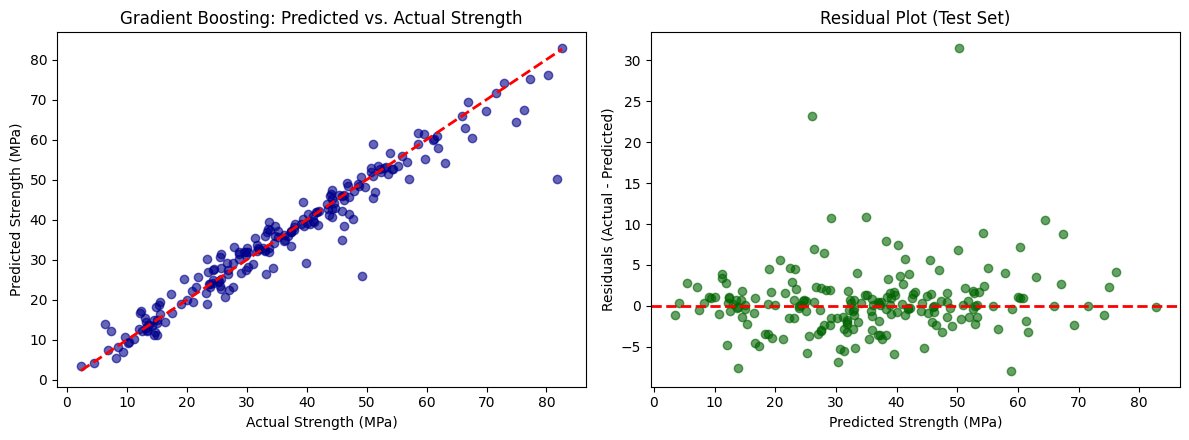

\nFeature Importances (Gradient Boosting):
water_cement_ratio    0.3494
log_age               0.2515
age                   0.1291
slag                  0.0783
superplasticizer      0.0638
fine_agg              0.0426
water                 0.0301
cement                0.0237
coarse_agg            0.0201
fly_ash               0.0115
dtype: float64
\nTop 5 Largest Prediction Errors:


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,water_cement_ratio,log_age,actual,predicted,abs_error
357,315.0,137.0,0.0,145.0,5.9,1130.0,745.0,28,0.460317,3.367296,81.75,50.281102,31.468898
371,200.0,200.0,0.0,190.0,0.0,1145.0,660.0,28,0.950000,3.367296,49.25,25.990770,23.259230
468,387.0,20.0,94.0,157.0,13.9,938.0,845.0,7,0.405685,2.079442,45.90,34.988442,10.911558
898,162.0,207.0,172.0,216.0,10.0,822.0,638.0,28,1.333333,3.367296,39.84,29.163789,10.676211
803,522.0,0.0,0.0,146.0,0.0,896.0,896.0,28,0.279693,3.367296,74.99,64.516795,10.473205


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(y_test, best_preds, alpha=0.6, color='darkblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Gradient Boosting: Predicted vs. Actual Strength')
axes[0].set_xlabel('Actual Strength (MPa)')
axes[0].set_ylabel('Predicted Strength (MPa)')

residuals = y_test - best_preds
axes[1].scatter(best_preds, residuals, alpha=0.6, color='darkgreen')
axes[1].axhline(0, color='r', linestyle='--', lw=2)
axes[1].set_title('Residual Plot (Test Set)')
axes[1].set_xlabel('Predicted Strength (MPa)')
axes[1].set_ylabel('Residuals (Actual - Predicted)')

plt.tight_layout()
plt.savefig('results_concrete.png', dpi=300)
plt.show()

importances = pd.Series(best_gbr.feature_importances_, index=X_train_eng.columns).sort_values(ascending=False)
print("\\nFeature Importances (Gradient Boosting):")
print(importances.round(4))

error_df = X_test_eng.copy()
error_df['actual'] = y_test
error_df['predicted'] = best_preds
error_df['abs_error'] = np.abs(y_test - best_preds)
print("\\nTop 5 Largest Prediction Errors:")
display(error_df.sort_values(by='abs_error', ascending=False).head(5))